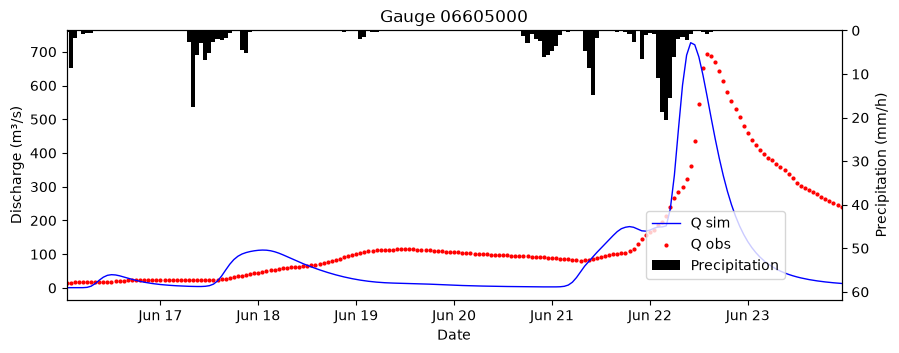

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

gauge = "06605000"
path_csv = f"outputs_event/ts.{gauge}.crest.csv"
path_fig = "outputs_event/figures"
os.makedirs(path_fig, exist_ok=True)

df = pd.read_csv(path_csv, index_col=0, parse_dates=True, na_values="NaN",
                 skipfooter=1, engine="python")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(df.index, df["Discharge(m^3 s^-1)"], color="blue", label="Q sim", linewidth=1)
ax.scatter(df.index, df["Observed(m^3 s^-1)"], color="red", label="Q obs", s=4)
ax.set_xlim(df.index.min(), df.index.max())
ax.set_xlabel("Date")
ax.set_ylabel("Discharge (m³/s)")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

ax2 = ax.twinx()
ax2.bar(df.index, df["Precip(mm h^-1)"], color="black", label="Precipitation", width=1/24)
ax2.set_ylabel("Precipitation (mm/h)")
ax2.set_ylim(df["Precip(mm h^-1)"].max() * 3, 0)

fig.legend(loc="lower right", bbox_to_anchor=(0.85, 0.15))
plt.title(f"Gauge {gauge}")
plt.savefig(f"{path_fig}/ts.{gauge}.png", bbox_inches="tight", dpi=200)
plt.show()